# Lab 05: The Dark Companion, Two Years Later

**ASTR 457, Fall 2026, posted Sat Oct 3, due Fri Oct 9 by Noon (extended) (fork → PR, as always)**

*Why this lab: every orbit in the literature, from Gaia's black-hole binaries to the planets David Charbonneau talked about on Tuesday, is a posterior distribution over six or seven parameters that nobody can write down in closed form. Sampling it, knowing when the sampler has actually converged, and turning the samples into a number with an honest error bar is the core professional skill of modern astrophysics, and the place where confident, fluent, wrong analyses are most common.*

On Day 1 you watched a star's radial velocity drift over ten nights and inferred an unseen companion from
the slope alone. This is that programme, two and a half years on. Every one of you has your own star:
`data/<your netid>.csv`, with columns `t_days` (time of each spectrum, from the first epoch), `rv_kms`
(the measured radial velocity) and `sigma_rv_kms` (the pipeline's per-epoch uncertainty). The star was
observed in three observing seasons over about 900 days, 28 to 44 epochs in all. It is a **single-lined
spectroscopic binary**: you see one star's lines, the companion contributes no light, and the visible star
follows a Keplerian orbit,

$$v_r(t) = \gamma + K\left[\cos\big(\nu(t) + \omega\big) + e\cos\omega\right],$$

with period $P$, semi-amplitude $K$, eccentricity $e$, argument of periastron $\omega$, a time of periastron
$T_p$, systemic velocity $\gamma$, and $\nu(t)$ the true anomaly (the angle around the orbit, which you get
from Kepler's equation; a function is provided). What you are really after is the **mass function**

$$f(M) = \frac{P K^3 (1 - e^2)^{3/2}}{2\pi G} = \frac{M_2^3 \sin^3 i}{(M_1 + M_2)^2},$$

a lower limit on the companion's mass, in solar masses. If it comes out above about $3\,M_\odot$ for a
Sun-like primary, you have a black hole candidate, the way Gaia BH1 was found (El-Badry et al. 2023, the Sep 8
colloquium). In the units of your file, $f(M) = 1.0361\times10^{-7}\,(1-e^2)^{3/2} K^3 P$ with $K$ in km/s
and $P$ in days.

I know your true $P$, $K$, $e$ and $f(M)$. You don't, your classmates' stars are different, and so is the
sampling. **One more thing I know and you don't: the quoted `sigma_rv_kms` is not the whole error.** Real
radial velocities carry an extra scatter, called jitter, from the star's own surface and from template
mismatch, and it is not in the pipeline number.

**How this is graded.** As always, on whether your answers are *right* and your uncertainties are *honest*:
your reported $P$, $K$, $e$ and $f(M)$ are compared to your truth in units of your own reported uncertainty.
Anti-sandbagging cap: your $\sigma_K$ may not exceed $3\times$ a reference posterior width I compute for your
dataset. Padded error bars lose points like overconfident ones.

**AI policy reminder.** Use whatever tools you like, including AI assistants, and document it in Part 4. You
may be selected to defend this lab orally; the defense is easy if you did the work.

Weights: Part 1 15%, Part 2 40%, Part 3 35%, Part 4 10%.


In [9]:
import os

print(os.getcwd())
print(os.listdir())

/Users/c2027/ASTR457_2026_Fall/submissions/cmewing2
['lab01.ipynb', 'lab03.ipynb', 'lab05.ipynb', 'Notes_for_Colloquium.pdf', 'lab02.ipynb', 'cmewing3.csv', 'cmewing2.csv', 'lab04.ipynb', 'inclass_day10_dwarf_agn.csv', '.ipynb_checkpoints', 'review_test_sep29.ipynb', 'ast.jpg']


In [32]:
!pip install emcee
!pip install corner
import numpy as np
import matplotlib.pyplot as plt
import emcee
import corner
from scipy.optimize import minimize
from astropy.timeseries import LombScargle


NETID = 'cmewing2'   # <-- set this
d = np.genfromtxt(f'../labs/05/data/{NETID}.csv', delimiter=',', names=True)
t, rv, sig = d['t_days'], d['rv_kms'], d['sigma_rv_kms']
print(f"{t.size} epochs over {t.max() - t.min():.0f} days; median quoted error {np.median(sig):.2f} km/s")

def kepler_rv(t, P, K, e, omega, Tp, gamma):
    """Radial velocity of the visible star in a Keplerian orbit.
    P period [d], K semi-amplitude [km/s], e eccentricity, omega argument of periastron [rad],
    Tp a time of periastron [d], gamma systemic velocity [km/s]. Solves Kepler's equation by Newton iteration."""
    M = 2. * np.pi * ((t - Tp) / P % 1.0)            # mean anomaly
    E = M.copy()                                     # eccentric anomaly
    for _ in range(30):
        E = E - (E - e * np.sin(E) - M) / (1. - e * np.cos(E))
    nu = 2. * np.arctan2(np.sqrt(1. + e) * np.sin(E / 2.), np.sqrt(1. - e) * np.cos(E / 2.))   # true anomaly
    return gamma + K * (np.cos(nu + omega) + e * np.cos(omega))

def mass_function(P, K, e):
    """f(M) in solar masses, for P in days and K in km/s."""
    return 1.0361e-7 * (1. - e**2)**1.5 * K**3 * P

FileNotFoundError: ../labs/05/data/cmewing2.csv not found.

## Part 1: Look first, then find the period (15%)

Plot the radial velocities against time with their error bars. Then find candidate orbital periods with a
Lomb-Scargle periodogram of the velocities (`astropy.timeseries.LombScargle`, Day 7's periodogram, formally
taught on Oct 20/22; for now it is a tool that ranks periods). Plot the periodogram. Then, for the best two or
three candidate periods, phase-fold the data and look.

Answer, in a few sentences: how many candidate periods are plausible from the periodogram alone, and why does
a Lomb-Scargle periodogram (which fits a *sinusoid*) not settle the question for an eccentric orbit? What
feature of the sampling (look at the gaps) produces the other peaks?


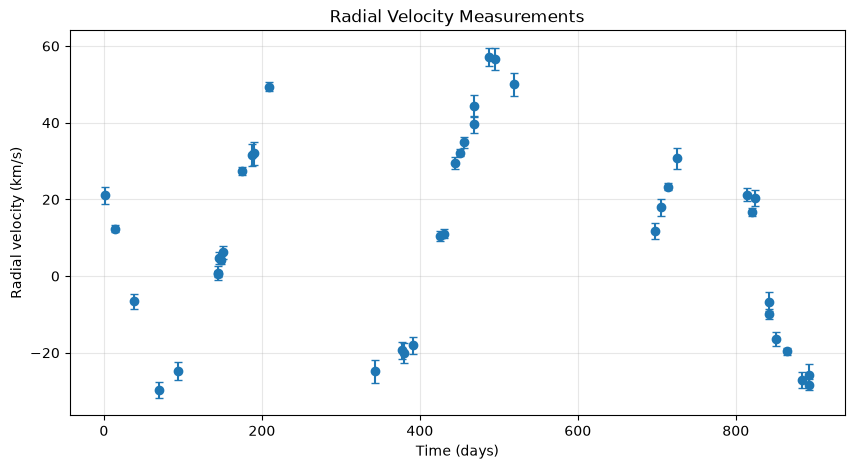

In [18]:
# Part 1: your work here

plt.figure(figsize=(10, 5))
plt.errorbar(t, rv, yerr=sig, fmt='o', capsize=3)
plt.xlabel('Time (days)')
plt.ylabel('Radial velocity (km/s)')
plt.title('Radial Velocity Measurements')
plt.grid(alpha=0.3)
plt.show()

**ANSWER (a few sentences):**

*There may be 2 to 3 candidates periods from the periodogram because multiple peaks can indicate possible orbital periods. The Lomb- Scargle periodogram does not settle well with eccentric orbit because the Lomb-Scargle periodogram fits to sinusoids and the eccentric orbit does not. The uneven sampling causes additional peaks.  *

## Part 2: Sample the posterior (40%)

Fit the six orbital parameters **plus a jitter term** $s$ with `emcee`. The likelihood for epoch $i$ is
Gaussian with variance $\sigma_i^2 + s^2$; write it out (including the $\log$ of the variance, which is not a
constant once $s$ is a parameter). You will need to:

1. **Write the log-likelihood, log-prior and log-posterior.** State every prior and justify it in one line
   each. Two traps: $\omega$ and $T_p$ are periodic ($T_p$ is only defined modulo $P$), and `emcee` does not
   wrap angles, so a hard prior wall at $0$ or $2\pi$ can cut a posterior mode in half. Either bound each of
   them within half a period of your starting value, or reparameterize with $\sqrt{e}\cos\omega$ and
   $\sqrt{e}\sin\omega$ (which also gives a uniform prior on $e$ without a wall at zero). Jitter is
   positive: sample $\ln s$.
2. **Start the walkers sensibly.** A maximum-likelihood fit from each plausible Part 1 period, with several
   starting $\omega$ and $T_p$ each, then compare the log-likelihoods; start the walkers in a small ball
   around the best one. That comparison is the check: report the log-likelihood of the runner-up.
3. **Run, then decide when it is done.** Compute the integrated autocorrelation time $\tau$ for every
   parameter (`sampler.get_autocorr_time`). Here $\tau$ is about 50 to 100 steps, so 64 walkers for
   10,000 steps is plenty (a few minutes) and `emcee`'s own rule is a chain longer than $50\tau$. A
   common choice is to discard a few $\tau$ as burn-in and thin by about $\tau/2$; say what you chose
   and why. Plot the chains. If $\tau$ cannot be estimated, your chain is too short; say so and fix it.
4. **Corner plot.** Which parameters are correlated, and why physically?
5. **Report** $P$, $K$, $e$, $\gamma$, the jitter $s$, and $f(M)$, each as a median and 68% interval.
   **$f(M)$ is computed for every posterior sample**, not from the medians of $P$, $K$ and $e$; explain in
   one sentence why that matters.
6. **Posterior predictive check.** Draw a few hundred orbits from the posterior and plot them over the data,
   phase-folded at the median period. Plot the normalized residuals with the *total* error bar
   $\sqrt{\sigma_i^2 + s^2}$. Is what is left noise?

**FINAL ANSWER:** $P = $ ___ $\pm$ ___ d, $K = $ ___ $\pm$ ___ km/s, $e = $ ___ $\pm$ ___, $\gamma = $ ___ $\pm$ ___ km/s, jitter $s = $ ___ $\pm$ ___ km/s, $f(M) = $ ___ $\pm$ ___ $M_\odot$. Is your companion a black-hole candidate? One sentence.


Candidate periods:
P = 270.30 days, power = 0.9811
P = 254.85 days, power = 0.7596
P = 287.74 days, power = 0.6189
P = 241.08 days, power = 0.4424
P = 118.93 days, power = 0.3223
P = 5.62 days, power = 0.2743
P = 17.46 days, power = 0.2633
P = 125.63 days, power = 0.2534


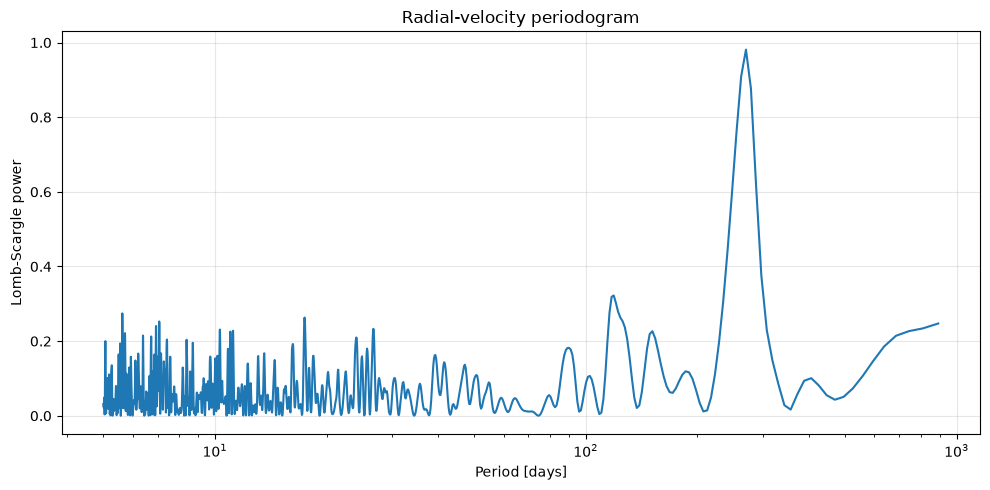

In [22]:
# Part 2: your work here
# Search for candidate orbital periods to initalize the fit. 
# Need to initalize the fit to use MCMC because it needs inital positions for its walkers.
# If they start in a poor region of parameter space, they may take a long time to reach the relevant posterior distribution, or fail to explore it adequately.

baseline = t.max() - t.min()

P_MIN = 5.0
P_MAX = baseline

ls = LombScargle(t, rv, dy=sig, fit_mean=True)

frequency, power = ls.autopower(
    minimum_frequency=1.0 / P_MAX,
    maximum_frequency=1.0 / P_MIN,
    samples_per_peak=10
)

periods = 1.0 / frequency

# Select the strongest distinct periodogram peaks
peak_order = np.argsort(power)[::-1]
PERIOD_CANDIDATES = []

for idx in peak_order:
    p = periods[idx]
    if all(abs(p - old) / old > 0.05
           for old in PERIOD_CANDIDATES):
        PERIOD_CANDIDATES.append(p)
    if len(PERIOD_CANDIDATES) >= 8:
        break

print("Candidate periods:")
for p in PERIOD_CANDIDATES:
    idx = np.argmin(abs(periods - p))
    print(f"P = {p:.2f} days, power = {power[idx]:.4f}")

plt.figure(figsize=(10, 5))
order = np.argsort(periods)
plt.plot(periods[order], power[order])
plt.xscale("log")
plt.xlabel("Period [days]")
plt.ylabel("Lomb-Scargle power")
plt.title("Radial-velocity periodogram")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
# Parameters sampled by emcee:
# theta = [P, K, h, k, phase, gamma, ln_s]
# h = sqrt(e)*cos(omega), k = sqrt(e)*sin(omega)
# phase is defined within one cycle relative to t_ref
# s = exp(ln_s)

t_ref = np.mean(t)
baseline = t.max() - t.min()

# Practical prior bounds; adjust if Part 1 specifies different bounds.
P_MIN = 5.0
P_MAX = baseline
K_MAX = 150.0
GAMMA_MIN, GAMMA_MAX = -150.0, 150.0
S_MIN, S_MAX = 0.01, 30.0

def unpack(theta):
    P, K, h, k, phase, gamma, ln_s = theta
    e = h**2 + k**2
    omega = np.arctan2(k, h)
    Tp = t_ref + P*phase
    s = np.exp(ln_s)
    return P, K, e, omega, Tp, gamma, s

def log_likelihood(theta):
    P, K, e, omega, Tp, gamma, s = unpack(theta)
    model = kepler_rv(t, P, K, e, omega, Tp, gamma)
    variance = sig**2 + s**2
    residual = rv - model
    return -0.5*np.sum(
        residual**2/variance + np.log(2*np.pi*variance)
    )

def log_prior(theta):
    P, K, h, k, phase, gamma, ln_s = theta
    e = h**2 + k**2

    if not (P_MIN < P < P_MAX):
        return -np.inf
    if not (0 < K < K_MAX):
        return -np.inf
    if not (0 <= e < 1):
        return -np.inf
    if not (-0.5 < phase < 0.5):
        return -np.inf
    if not (GAMMA_MIN < gamma < GAMMA_MAX):
        return -np.inf
    if not (np.log(S_MIN) < ln_s < np.log(S_MAX)):
        return -np.inf

    return 0.0

def log_posterior(theta):
    lp = log_prior(theta)
    if not np.isfinite(lp):
        return -np.inf
    ll = log_likelihood(theta)
    return lp + ll if np.isfinite(ll) else -np.inf

## Start the walkers sensibly

In [28]:
#I choose these to be my periods because they should the strongest distinct peaks in the Lomb-Scargle periodogram.
PERIOD_CANDIDATES = [270.30, 254.85]
    # Enter your plausible Part 1 periods, e.g. 120.0, 250.0


if len(PERIOD_CANDIDATES) == 0:
    raise ValueError("Enter the plausible Part 1 periods first.")

e_guesses = [0.05, 0.3, 0.6, 0.85]
omega_guesses = np.linspace(-np.pi, np.pi, 8, endpoint=False)
Tp_offsets = [-0.25, 0.0, 0.25]  # fractions of P from t_ref

bounds = [
    (P_MIN + 1e-6, P_MAX - 1e-6),
    (1e-5, K_MAX),
    (-0.999, 0.999),
    (-0.999, 0.999),
    (-0.5, 0.5),
    (GAMMA_MIN, GAMMA_MAX),
    (np.log(S_MIN), np.log(S_MAX))
]

constraints = [{
    "type": "ineq",
    "fun": lambda x: 1 - x[2]**2 - x[3]**2
}]

gamma0 = np.median(rv)
K0 = max(np.std(rv)*np.sqrt(2), 1.0)
lns0 = np.log(max(np.median(sig), 0.1))
fits = []

for Pg in PERIOD_CANDIDATES:
    for eg in e_guesses:
        for wg in omega_guesses:
            for offset in Tp_offsets:
                Tp_guess = t_ref + offset*Pg
                phase_guess = ((Tp_guess-t_ref)/Pg + 0.5) % 1.0 - 0.5

                x0 = np.array([
                    Pg, K0,
                    np.sqrt(eg)*np.cos(wg),
                    np.sqrt(eg)*np.sin(wg),
                    phase_guess, gamma0, lns0
                ])

                result = minimize(
                    lambda x: -log_likelihood(x),
                    x0,
                    method="SLSQP",
                    bounds=bounds,
                    constraints=constraints,
                    options={"maxiter": 3000, "ftol": 1e-9}
                )

                if result.success and np.isfinite(result.fun):
                    fits.append({
                        "logL": -result.fun,
                        "x": result.x.copy()
                    })

if len(fits) < 2:
    raise RuntimeError("Too few successful fits; check starts and convergence.")

fits.sort(key=lambda f: f["logL"], reverse=True)

# Keep only distinct fitted solutions
distinct = []
for fit in fits:
    x = fit["x"]
    duplicate = False

    for old in distinct:
        y = old["x"]
        if (
            abs(x[0]-y[0])/max(abs(x[0]), 1.0) < 1e-3
            and abs(x[1]-y[1]) < 1e-2
            and abs((x[2]**2+x[3]**2)-(y[2]**2+y[3]**2)) < 1e-3
            and abs(x[4]-y[4]) < 1e-3
            and abs(x[5]-y[5]) < 1e-2
            and abs(x[6]-y[6]) < 1e-2
        ):
            duplicate = True
            break

    if not duplicate:
        distinct.append(fit)

if len(distinct) < 2:
    raise RuntimeError(
        "Only one distinct solution found; try more starting periods or phases."
    )

best, runner_up = distinct[0], distinct[1]

print("Best log-likelihood:", best["logL"])
print("Runner-up log-likelihood:", runner_up["logL"])
print("Difference:", best["logL"] - runner_up["logL"])
print("Best-fit period (days):", best["x"][0])
print("Runner-up period (days):", runner_up["x"][0])


/var/folders/79/f40vsy253hj8h9gqrb233j580000gn/T/ipykernel_34266/215331338.py:24: RuntimeWarning: invalid value encountered in sqrt
  nu = 2. * np.arctan2(np.sqrt(1. + e) * np.sin(E / 2.), np.sqrt(1. - e) * np.cos(E / 2.))   # true anomaly


Best log-likelihood: -101.0578939889869
Runner-up log-likelihood: -115.7163478893569
Difference: 14.658453900369992
Best-fit period (days): 270.24054629694825
Runner-up period (days): 269.9146298099326


In [25]:

bounds = [
    P_BOUNDS, (0.1, 150),
    (-0.999, 0.999), (-0.999, 0.999),
    (-0.499, 0.499), (-100, 100),
    (np.log(0.02), np.log(20))
]

solutions = []

for P0 in PERIOD_CANDIDATES:
    for phase0 in [-0.4, -0.2, 0.0, 0.2, 0.4]:
        for e0 in [0.05, 0.4, 0.75]:
            omega0 = 0.5

            x0 = np.array([
                P0,
                max(5., (rv.max() - rv.min()) / 2),
                np.sqrt(e0)*np.cos(omega0),
                np.sqrt(e0)*np.sin(omega0),
                phase0,
                np.median(rv),
                np.log(2.)
            ])

            result = minimize(
                lambda x: -log_posterior(x)
                if np.isfinite(log_posterior(x)) else 1e100,
                x0,
                method="SLSQP",
                bounds=bounds,
                constraints=[{
                    "type": "ineq",
                    "fun": lambda x: 1.0 - x[2]**2 - x[3]**2
                }],
                options={"maxiter": 3000, "ftol": 1e-9}
            )

            if result.success and np.isfinite(log_posterior(result.x)):
                solutions.append(result)

if not solutions:
    raise RuntimeError(
        "No successful fits. Check the period search and parameter bounds."
    )

solutions.sort(
    key=lambda result: log_likelihood(result.x),
    reverse=True
)

best = solutions[0]

print("Best-fit parameters:")
print(unpack(best.x))
print("Best log-likelihood:", log_likelihood(best.x))

# Identify a runner-up with a meaningfully different period.
runner_up = next(
    (sol for sol in solutions[1:]
     if abs(sol.x[0] - best.x[0]) > 0.02 * best.x[0]),
    None
)

if runner_up is not None:
    print("Runner-up period:", runner_up.x[0], "days")
    print("Runner-up log-likelihood:", log_likelihood(runner_up.x))
else:
    print("No distinct runner-up period found in these starts.")


Best-fit parameters:
(np.float64(270.24054446381604), np.float64(41.01237218035105), np.float64(0.11005343046651125), np.float64(0.8226408848260847), np.float64(526.793511432362), np.float64(10.70238576412277), np.float64(1.7058411961311015))
Best log-likelihood: -101.05789398923602
Runner-up period: 387.1720818072044 days
Runner-up log-likelihood: -197.81160424131596


In [26]:
#Emcee

np.random.seed(42)

ndim = 7
nwalkers = 64
nsteps = 10000

center = best.x.copy()
scale = np.array([
    0.002*center[0], 0.02*center[1],
    0.01, 0.01, 0.01, 0.2, 0.03
])

initial = center + scale*np.random.randn(nwalkers, ndim)

for j in range(nwalkers):
    tries = 0
    while not np.isfinite(log_posterior(initial[j])):
        initial[j] = center + scale*np.random.randn(ndim)
        tries += 1
        if tries > 10000:
            raise RuntimeError("Could not initialize valid walkers.")

sampler = emcee.EnsembleSampler(
    nwalkers, ndim, log_posterior
)

sampler.run_mcmc(initial, nsteps, progress=True)

try:
    tau = sampler.get_autocorr_time(tol=0)
    print("Autocorrelation times:", tau)
    print("Steps / autocorrelation time:", nsteps/tau)

    burn = int(5*np.max(tau))
    thin = max(1, int(np.min(tau)/2))

    if np.any(nsteps < 50*tau):
        print("WARNING: chain is shorter than 50 autocorrelation times.")
except Exception as exc:
    print("Could not reliably estimate autocorrelation time:", exc)
    print("Run a longer chain before reporting final uncertainties.")
    burn, thin = nsteps//2, 1

if burn >= nsteps:
    raise RuntimeError("Chain too short for the estimated burn-in.")

flat = sampler.get_chain(
    discard=burn, thin=thin, flat=True
)

print("Posterior samples:", len(flat))


100%|█████████████████████████████████████| 10000/10000 [03:43<00:00, 44.65it/s]


Autocorrelation times: [ 80.4471079   78.41249018  92.8690141  101.84069323 104.02448736
  78.9580582   83.24254531]
Steps / autocorrelation time: [124.30527661 127.53070305 107.67854162  98.1925759   96.13121154
 126.64951783 120.13087734]
Posterior samples: 15552


In [27]:
#Parameters and Mass Function

physical = np.array([unpack(row) for row in flat])

P_s = physical[:, 0]
K_s = physical[:, 1]
e_s = physical[:, 2]
omega_s = physical[:, 3]
Tp_s = physical[:, 4]
gamma_s = physical[:, 5]
jitter_s = physical[:, 6]

# Calculate the mass function for EVERY posterior sample.
fM_s = mass_function(P_s, K_s, e_s)

samples = np.column_stack([
    P_s, K_s, e_s, gamma_s, jitter_s, fM_s
])

names = [
    "P [days]", "K [km/s]", "e",
    "gamma [km/s]", "jitter s [km/s]",
    "f(M) [solar masses]"
]

# Calculate the mass function for every posterior sample
fM_samples = mass_function(P_s, K_s, e_s)

# Include all requested parameters in the report
names = ["P (days)", "K (km/s)", "e", "gamma (km/s)",
         "jitter (km/s)", "f(M) (solar masses)"]

samples = np.column_stack([P_s, K_s, e_s, gamma_s, jitter_s, fM_samples])

for name, values in zip(names, samples.T):
    q16, median, q84 = np.percentile(values, [16, 50, 84])
    print(f"{name}: {median:.6g} (+{q84-median:.4g}, -{median-q16:.4g})")
    
for name, values in zip(names, samples.T):
    q16, median, q84 = np.percentile(values, [16, 50, 84])
    uncertainty = (q84 - q16) / 2
    print(f"{name} = {median:.6g} ± {uncertainty:.4g}")


P (days): 270.249 (+0.5118, -0.5085)
K (km/s): 40.9336 (+0.8596, -0.8584)
e: 0.108827 (+0.01871, -0.01813)
gamma (km/s): 10.6554 (+0.5208, -0.5335)
jitter (km/s): 2.00394 (+0.5055, -0.4495)
f(M) (solar masses): 1.88598 (+0.1159, -0.1135)
P (days) = 270.249 ± 0.5102
K (km/s) = 40.9336 ± 0.859
e = 0.108827 ± 0.01842
gamma (km/s) = 10.6554 ± 0.5272
jitter (km/s) = 2.00394 ± 0.4775
f(M) (solar masses) = 1.88598 ± 0.1147


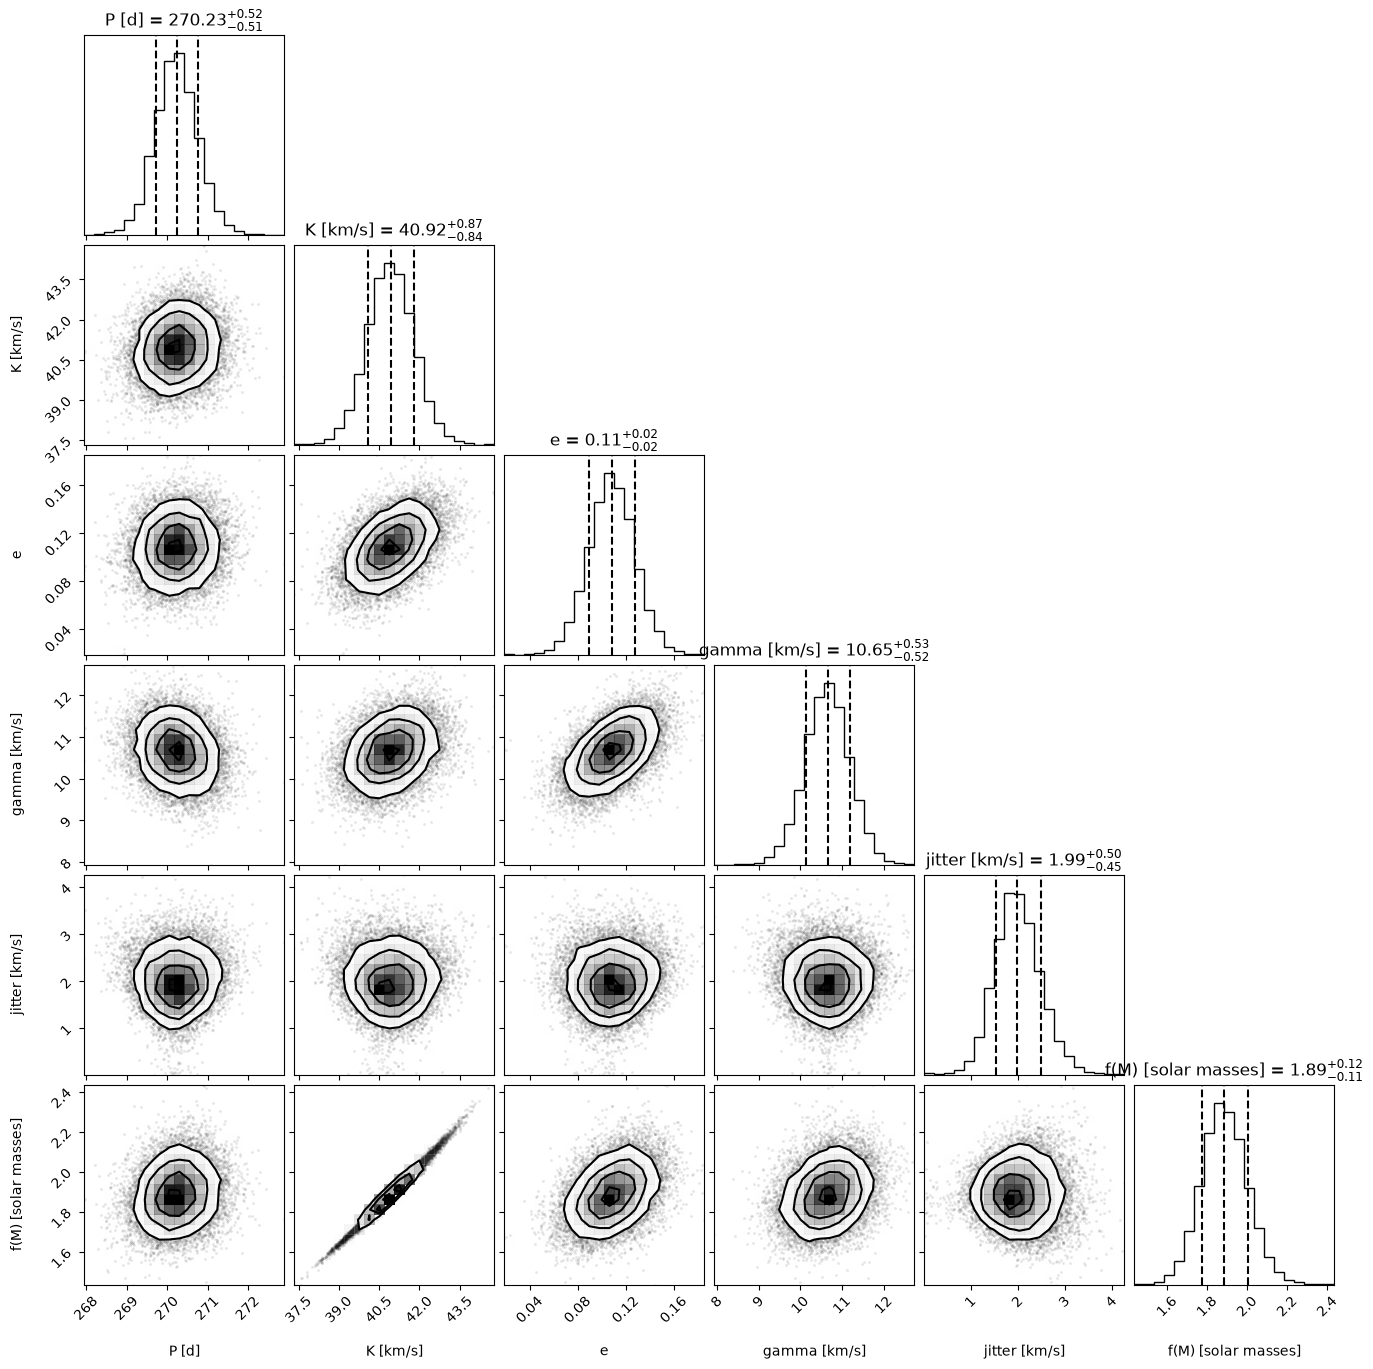

In [12]:
#Corner Plot
fig = corner.corner(
    samples,
    labels=[
        "P [d]", "K [km/s]", "e",
        "gamma [km/s]", "jitter [km/s]",
        "f(M) [solar masses]"
    ],
    quantiles=[0.16, 0.5, 0.84],
    show_titles=True
)
plt.show()

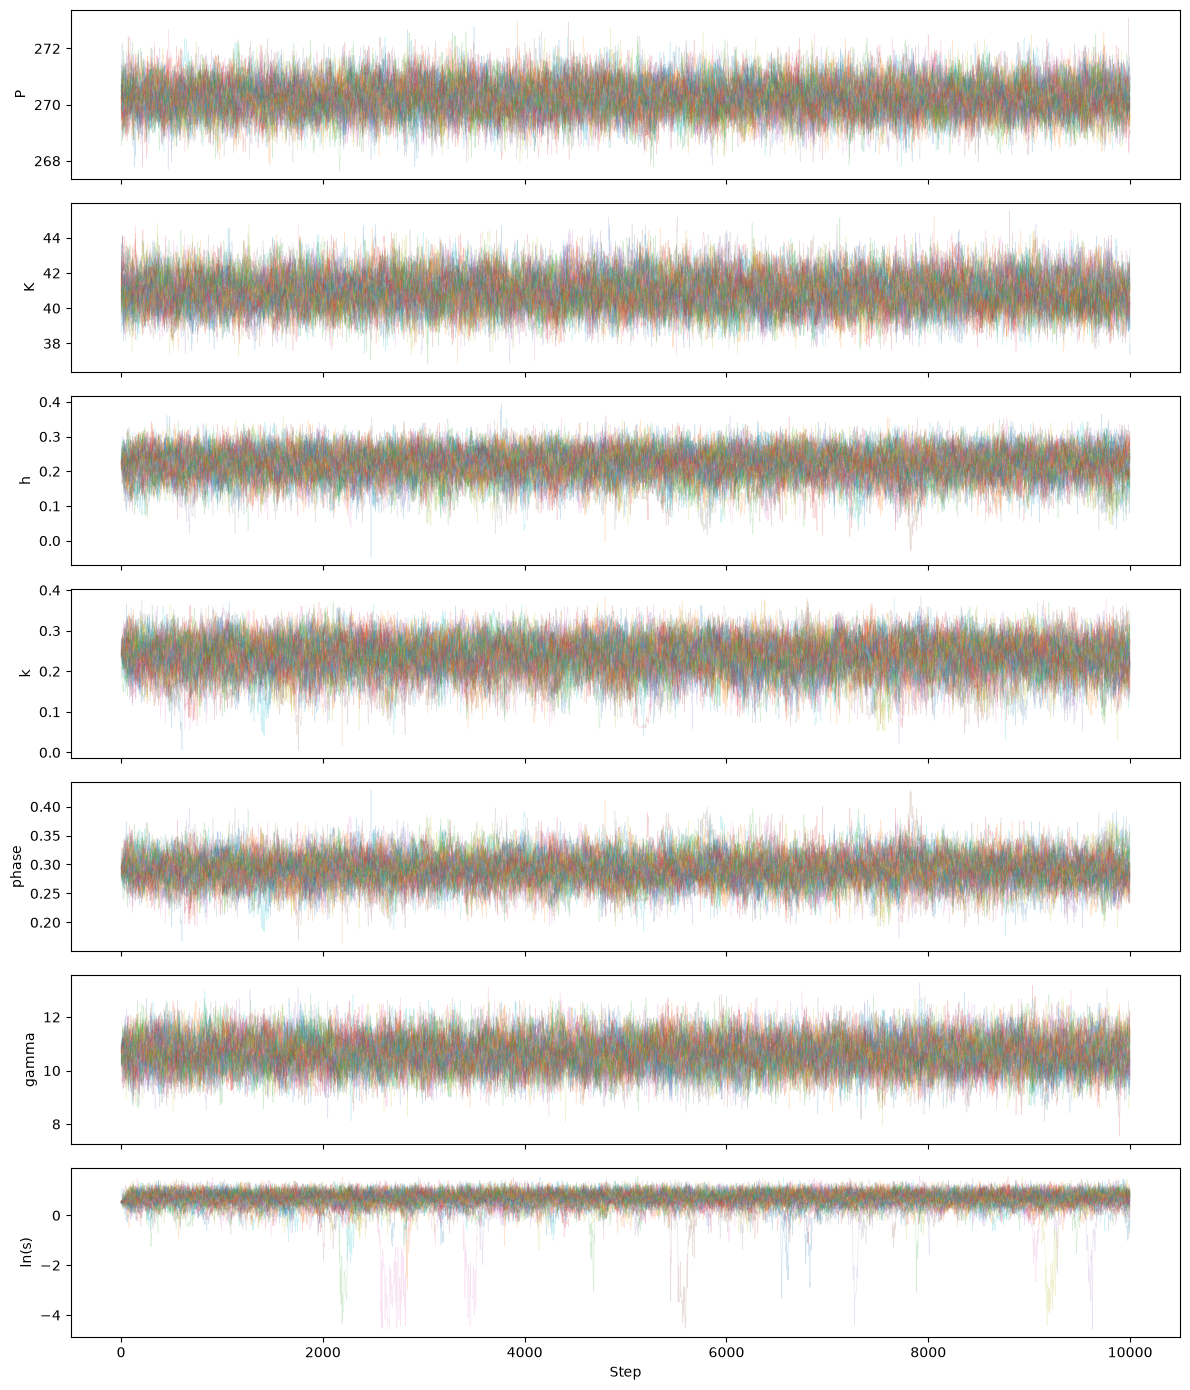

In [11]:
#Trace Plot 
chain = sampler.get_chain()

labels = ["P", "K", "h", "k", "phase", "gamma", "ln(s)"]

fig, axes = plt.subplots(
    ndim, 1, figsize=(12, 14), sharex=True
)

for j, ax in enumerate(axes):
    ax.plot(chain[:, :, j], alpha=0.2, lw=0.4)
    ax.set_ylabel(labels[j])

axes[-1].set_xlabel("Step")
plt.tight_layout()
plt.show()

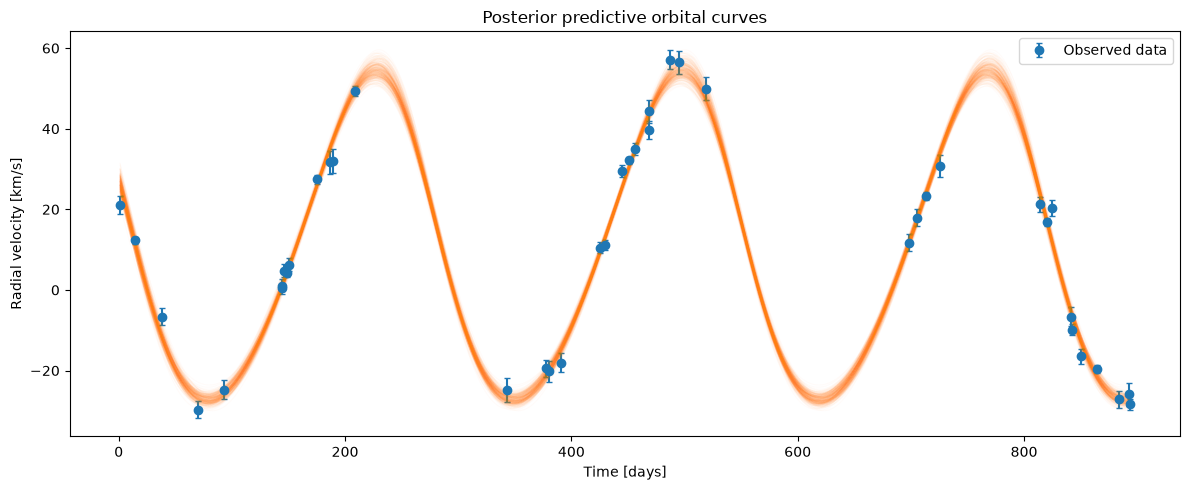

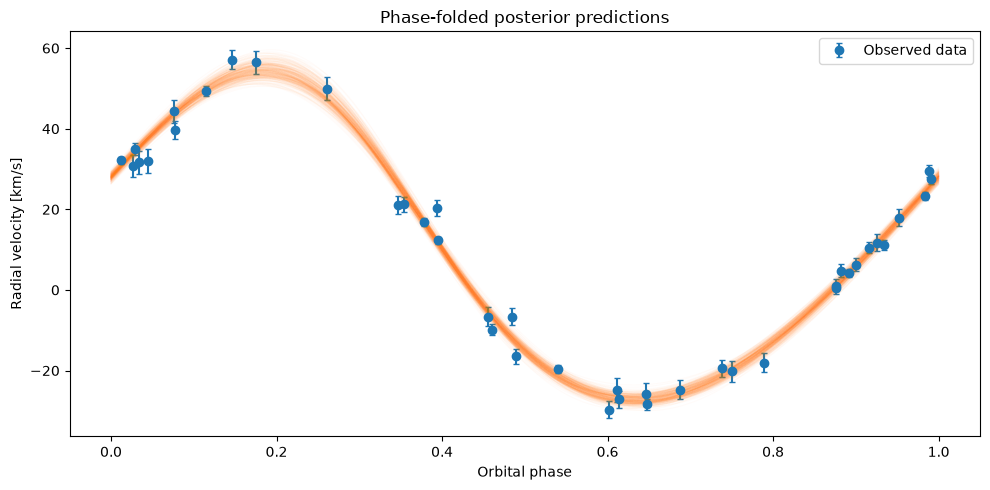

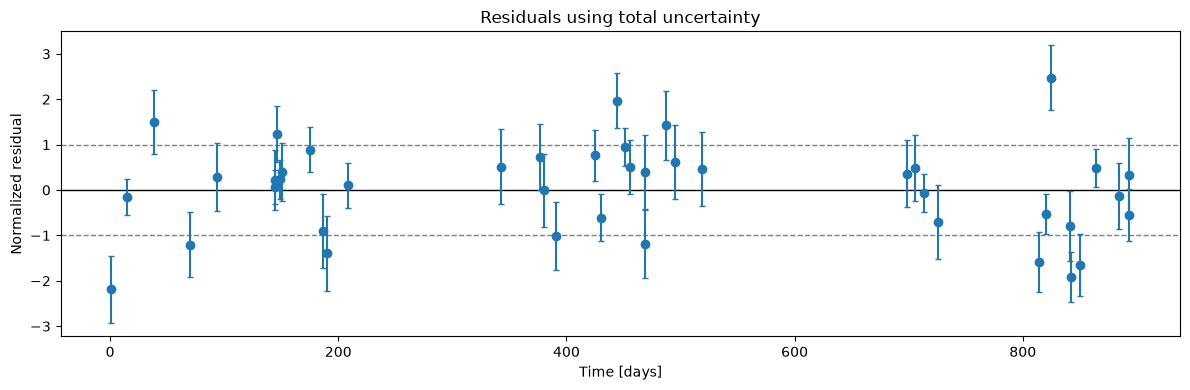

In [13]:
# Posterior predictive orbital curves and residuals


rng = np.random.default_rng(123)
nplot = min(300, len(flat))
chosen = rng.choice(len(flat), size=nplot, replace=False)

tgrid = np.linspace(t.min(), t.max(), 1500)

plt.figure(figsize=(12, 5))
plt.errorbar(t, rv, yerr=sig, fmt='o', capsize=2,
             label="Observed data")

for j in chosen:
    Pj, Kj, ej, oj, Tpj, gj, sj = unpack(flat[j])
    plt.plot(
        tgrid, kepler_rv(tgrid, Pj, Kj, ej, oj, Tpj, gj),
        color="C1", alpha=0.025, lw=0.8
    )

plt.xlabel("Time [days]")
plt.ylabel("Radial velocity [km/s]")
plt.title("Posterior predictive orbital curves")
plt.legend()
plt.tight_layout()
plt.show()

# Phase-fold at the posterior median period.
Pmed = np.median(P_s)
phase_obs = ((t - t_ref) / Pmed) % 1
phase_grid = np.linspace(0, 1, 500)

plt.figure(figsize=(10, 5))
plt.errorbar(phase_obs, rv, yerr=sig, fmt='o', capsize=2,
             label="Observed data")

for j in chosen:
    Pj, Kj, ej, oj, Tpj, gj, sj = unpack(flat[j])
    tphase = t_ref + phase_grid * Pmed
    plt.plot(
        phase_grid,
        kepler_rv(tphase, Pj, Kj, ej, oj, Tpj, gj),
        color="C1", alpha=0.025, lw=0.8
    )

plt.xlabel("Orbital phase")
plt.ylabel("Radial velocity [km/s]")
plt.title("Phase-folded posterior predictions")
plt.legend()
plt.tight_layout()
plt.show()

# Normalized residuals using total uncertainty, including jitter.
# Choose an actual posterior sample close to the multivariate median.
scale_samples = np.std(samples, axis=0)
scale_samples[scale_samples == 0] = 1.0

z = (samples - np.median(samples, axis=0)) / scale_samples
representative_idx = np.argmin(np.sum(z**2, axis=1))

Pm, Km, em, om, Tpm, gm, sj = unpack(flat[representative_idx])

residual = rv - kepler_rv(t, Pm, Km, em, om, Tpm, gm)
total_error = np.sqrt(sig**2 + sj**2)
normalized_residual = residual / total_error

plt.figure(figsize=(12, 4))
plt.axhline(0, color="black", lw=1)
plt.axhline(1, color="gray", ls="--", lw=1)
plt.axhline(-1, color="gray", ls="--", lw=1)
plt.errorbar(
    t, normalized_residual,
    yerr=sig/total_error,
    fmt="o", capsize=2
)
plt.xlabel("Time [days]")
plt.ylabel("Normalized residual")
plt.title("Residuals using total uncertainty")
plt.tight_layout()
plt.show()


**FINAL ANSWER:** $P = $ ___ $\pm$ ___ d, $K = $ ___ $\pm$ ___ km/s, $e = $ ___ $\pm$ ___ , $\gamma = $ ___ $\pm$ ___ km/s, $s = $ ___ $\pm$ ___ km/s, $f(M) = $ ___ $\pm$ ___ $M_\odot$

**Black-hole candidate?** *one sentence*

In [19]:
# Calculate uncertainties for all orbital parameters
print("Final Answer:")
for name, values in zip(names, samples.T):
    q16, median, q84 = np.percentile(values, [16, 50, 84])
    uncertainty = (q84 - q16) / 2
    print(f"{name} = {median:.6g} ± {uncertainty:.4g}")


P [days] = 270.232 ± 0.5134
K [km/s] = 40.9244 ± 0.852
e = 0.108294 ± 0.01886
gamma [km/s] = 10.6495 ± 0.5249
jitter s [km/s] = 1.98753 ± 0.4729
f(M) [solar masses] = 1.88502 ± 0.1126


## Part 3: The referee report (35%)

The file `ai_solution.ipynb` in this directory is a complete, tidy, confident MCMC analysis of this exact
problem, produced by an AI assistant. It runs top to bottom without errors, the corner plot is handsome, and
the prose is fluent. It is also wrong, in at least **three** distinct, substantive ways (cosmetic nitpicks and
style don't count; "it used 24 walkers and I used 32" is not a finding).

Write a referee report:

1. **Identify** at least three substantive statistical errors.
2. **Demonstrate** each one quantitatively on *your* dataset: show, with a number or a plot, what the error
   does to the inference. For a sampler, "demonstrate" usually means running it the wrong way and the right
   way and comparing. A demonstration can come out negative: if an error turns out not to move *your*
   numbers, showing that, and saying what it would take for it to bite, is a valid finding.
3. **State** the correct treatment (you built it in Part 2).

Third time you have done this. You should be finding these in minutes now.


In [ ]:
# Part 3: your work here


**REFEREE REPORT:**

*your report goes here*

## Part 4: AI-use appendix and verification plan (10%)

1. **AI use**: which tools did you use, for what, what did they get wrong, and how did you catch it? Honesty
   is graded; "I didn't use any" is fine if true.
2. **Reflection (new from this lab on, two or three sentences)**: what did you use AI for in this lab, and
   what would have gone wrong in your answer if you had not checked its output? Name the specific thing, not
   "it could have made a mistake".
3. **Verification plan**: the checks you ran before trusting your Part 2 numbers, and what failure would have
   looked like for each. One you should seriously consider: generate a synthetic RV curve with parameters
   you choose, at *your* epochs, run your whole Part 2 pipeline on it, and see whether the 68% intervals
   contain what you put in. With seven parameters and one realisation, expect about five of seven inside
   their 68% intervals; one pull of 2.5σ is not a failure by itself. Failure looks systematic: the same
   parameter off in the same direction every time, or an interval that never contains the truth.


**AI-USE APPENDIX:**

*your answer goes here*

**REFLECTION:**

*Many errors in the code when directly copied from ChatBGT like variables not being identified.*

**VERIFICATION PLAN:**

*your plan goes here*